<a href="https://colab.research.google.com/github/x-rohanpatil/DAV-lab-/blob/main/Davlab_09_decisiontree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import  pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier ,plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


***sample dataset***

In [10]:
data = {
    'StudyHours': [
        4, 2, 6, 3, 8, 5, 1, 7, 4, 9,
        3, 6, 2, 8, 5, 7, 1, 4, 9, 6,
        3, 5, 8, 2, 7, 4, 6, 1, 9, 5
    ],

    'Attendance': [
        75, 45, 90, 60, 95, 82, 35, 88, 70, 98,
        55, 85, 48, 92, 78, 94, 40, 72, 99, 87,
        58, 80, 96, 50, 91, 68, 89, 30, 97, 83
    ],

    'PrevMarks': [
        55, 28, 82, 42, 95, 68, 18, 88, 52, 98,
        35, 78, 25, 92, 65, 90, 20, 58, 96, 85,
        38, 72, 94, 30, 86, 48, 80, 15, 99, 70
    ],

    'Result': [
        'Pass', 'Fail', 'Pass', 'Fail', 'Pass',
        'Pass', 'Fail', 'Pass', 'Pass', 'Pass',
        'Fail', 'Pass', 'Fail', 'Pass', 'Pass',
        'Pass', 'Fail', 'Pass', 'Pass', 'Pass',
        'Fail', 'Pass', 'Pass', 'Fail', 'Pass',
        'Fail', 'Pass', 'Fail', 'Pass', 'Pass'
    ]
}

df = pd.DataFrame(data)

***dataset in rows and columns***

In [11]:
display(df)

,StudyHours,Attendance,PrevMarks,Result
0,4,75,55,Pass
1,2,45,28,Fail
2,6,90,82,Pass
3,3,60,42,Fail
4,8,95,95,Pass
5,5,82,68,Pass
6,1,35,18,Fail
7,7,88,88,Pass
8,4,70,52,Pass
9,9,98,98,Pass


***Splitting into input and output***

In [12]:
x = df[['StudyHours','Attendance','PrevMarks']]
y = df['Result']

print("INput features: ")
display(x.head())

print("Target: ")
display(y.head())

INput features: 


,StudyHours,Attendance,PrevMarks
0,4,75,55
1,2,45,28
2,6,90,82
3,3,60,42
4,8,95,95


Target: 


,Result
0,Pass
1,Fail
2,Pass
3,Fail
4,Pass


***Splitting the dataset to train***

In [14]:
x_tr, x_te, y_tr, y_te = train_test_split(
    x,y,test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training records:", len(x_tr))
print("Testing records:", len(x_te))

Training records: 24
Testing records: 6


**Training the model with .fit in decision tree classifier**

In [15]:
tree_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_clf.fit(x_tr, y_tr)

print("Decision Tree Classifier trained successfully.")

Decision Tree Classifier trained successfully.


**Make predictions**

In [17]:
y_pred = tree_clf.predict(x_te)
comparison = pd.DataFrame({
    'Actual Result': y_te.values,
    'Predicted': y_pred
})

display(comparison)


,Actual Result,Predicted
0,Fail,Fail
1,Pass,Pass
2,Pass,Pass
3,Pass,Pass
4,Fail,Fail
5,Pass,Pass


***report***

In [18]:
print("Accuracy:", round(accuracy_score(y_te, y_pred),3))
print("\nClassification Report:")
print(classification_report(y_te, y_pred,zero_division=0))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



***visualisation***

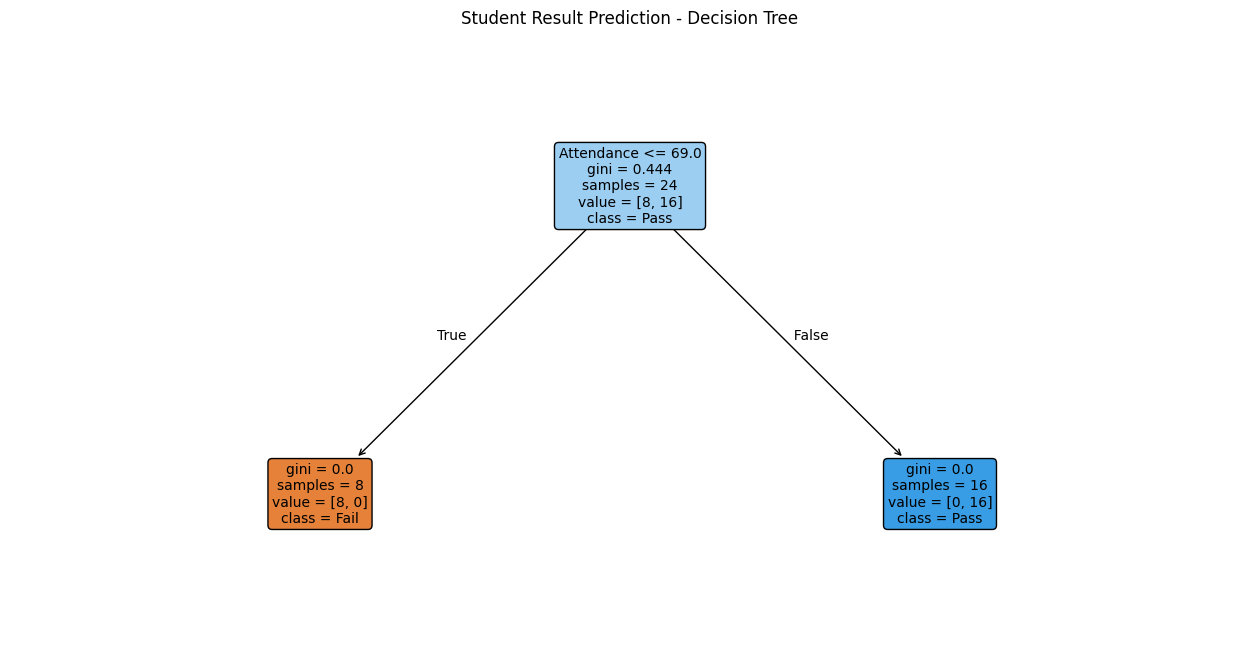

In [22]:
# Visualize Decision Tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree_clf,
    feature_names=x.columns,
    class_names=[str(c) for c in tree_clf.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Student Result Prediction - Decision Tree")
plt.show()